# 🌱 Project 

Plant Disease Detection Using Convolutional Neural Networks (CNN)

To develop a CNN-based deep learning model that can analyze images of plant leaves and automatically classify them into different disease/healthy categories using the PlantVillage dataset.

# Import Libraries

In [2]:
import tensorflow as tf
from tensorflow import keras
import os
import matplotlib.pyplot as plt

# Collect Dataset

In [3]:
dataset_path = r"C:\Users\Arjun Singh Tomar\Downloads\plantvillage\dataset"

In [4]:
print(os.listdir(dataset_path))

['test', 'train', 'validation']


# Train Dataset

In [5]:
train_path = os.path.join(dataset_path,"train")

train_ds = tf.keras.utils.image_dataset_from_directory(
    train_path,
    labels = "inferred",
    label_mode = "int",
    image_size = (128,128),
    batch_size = 32,
    seed = 42
)

Found 16504 files belonging to 15 classes.


In [6]:
class_names = train_ds.class_names

In [7]:
print(class_names)

['Pepper__bell___Bacterial_spot', 'Pepper__bell___healthy', 'Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy', 'Tomato_Bacterial_spot', 'Tomato_Early_blight', 'Tomato_Late_blight', 'Tomato_Leaf_Mold', 'Tomato_Septoria_leaf_spot', 'Tomato_Spider_mites_Two_spotted_spider_mite', 'Tomato__Target_Spot', 'Tomato__Tomato_YellowLeaf__Curl_Virus', 'Tomato__Tomato_mosaic_virus', 'Tomato_healthy']


In [8]:
print(len(class_names))

15


# Validation Dataset

In [9]:
validation_path = os.path.join(dataset_path,"validation")

validation_ds = tf.keras.utils.image_dataset_from_directory(
    validation_path,
    labels = "inferred",
    label_mode = "int",
    batch_size = 32,
    image_size = (128,128),
    seed = 42
)

Found 2070 files belonging to 15 classes.


In [10]:
class_names2 = validation_ds.class_names

In [11]:
print(class_names)

['Pepper__bell___Bacterial_spot', 'Pepper__bell___healthy', 'Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy', 'Tomato_Bacterial_spot', 'Tomato_Early_blight', 'Tomato_Late_blight', 'Tomato_Leaf_Mold', 'Tomato_Septoria_leaf_spot', 'Tomato_Spider_mites_Two_spotted_spider_mite', 'Tomato__Target_Spot', 'Tomato__Tomato_YellowLeaf__Curl_Virus', 'Tomato__Tomato_mosaic_virus', 'Tomato_healthy']


In [12]:
print(len(class_names))

15


# Test Dataset

In [13]:
test_path = os.path.join(dataset_path,"test")

test_ds = tf.keras.utils.image_dataset_from_directory(
    test_path,
    labels = "inferred",
    label_mode = "int",
    batch_size = 32,
    image_size = (128,128),
    seed = 42
)

Found 2064 files belonging to 15 classes.


In [14]:
class_names3 = validation_ds.class_names

In [15]:
print(len(class_names))

15


In [16]:
print(class_names)

['Pepper__bell___Bacterial_spot', 'Pepper__bell___healthy', 'Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy', 'Tomato_Bacterial_spot', 'Tomato_Early_blight', 'Tomato_Late_blight', 'Tomato_Leaf_Mold', 'Tomato_Septoria_leaf_spot', 'Tomato_Spider_mites_Two_spotted_spider_mite', 'Tomato__Target_Spot', 'Tomato__Tomato_YellowLeaf__Curl_Virus', 'Tomato__Tomato_mosaic_virus', 'Tomato_healthy']


In [17]:
print("Train:", tf.data.experimental.cardinality(train_ds).numpy())
print("Validation:", tf.data.experimental.cardinality(validation_ds).numpy())
print("Test:", tf.data.experimental.cardinality(test_ds).numpy())

Train: 516
Validation: 65
Test: 65


# Load Image

In [19]:
for images,labels in train_ds.take(1):
    print("Image shape",images.shape)
    print("label shape",labels.shape)

Image shape (32, 128, 128, 3)
label shape (32,)


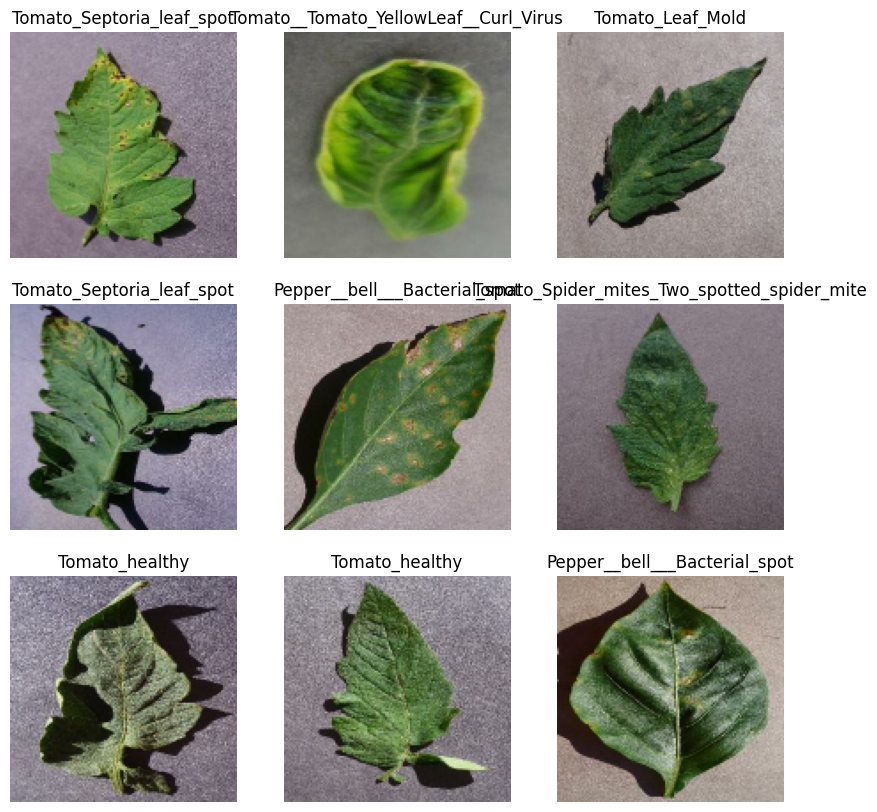

In [22]:
for images,labels in train_ds.take(1):
    plt.figure(figsize=(10,10))

    for i in range(9):
        ax = plt.subplot(3,3,i+1);
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[int(labels[i])])
        plt.axis("off")
    plt.show()

# Normalization

In [26]:
normalization_layers = keras.layers.Rescaling(1./255)

train_ds = train_ds.map(
    lambda images,labels : (normalization_layers(images),labels)
)

validation_ds = validation_ds.map(
    lambda images,labels : (normalization_layers(images),labels)
)

test_ds = test_ds.map(
    lambda images,labels : (normalization_layers(images),labels)
)

# CNN Model

In [33]:
from keras import Sequential
from keras.layers import Dense,Flatten,Conv2D,MaxPooling2D,Dropout

In [34]:
model = Sequential()

model.add(Conv2D(32,kernel_size=(3,3),padding = 'valid',activation='relu',input_shape=(128,128,3)))
model.add(MaxPooling2D(pool_size=(2,2),strides=2,padding='valid'))

model.add(Conv2D(64,kernel_size=(3,3),padding = 'valid',activation='relu'))
model.add(MaxPooling2D(pool_size=(2,2),strides=2,padding='valid'))

model.add(Conv2D(128,kernel_size=(3,3),padding = 'valid',activation='relu'))
model.add(MaxPooling2D(pool_size=(2,2),strides=2,padding='valid'))

model.add(Flatten())

model.add(Dense(128,activation='relu'))
model.add(Dropout(0.5)),

model.add(Dense(len(class_names),activation='softmax'))

In [35]:
model.summary()

Model: "sequential_2"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_6 (Conv2D)           (None, 126, 126, 32)      896       
                                                                 
 max_pooling2d_6 (MaxPooling  (None, 63, 63, 32)       0         
 2D)                                                             
                                                                 
 conv2d_7 (Conv2D)           (None, 61, 61, 64)        18496     
                                                                 
 max_pooling2d_7 (MaxPooling  (None, 30, 30, 64)       0         
 2D)                                                             
                                                                 
 conv2d_8 (Conv2D)           (None, 28, 28, 128)       73856     
                                                                 
 max_pooling2d_8 (MaxPooling  (None, 14, 14, 128)     

# Compile Model

In [38]:
model.compile(
    optimizer = 'adam',
    loss = 'sparse_categorical_crossentropy',
    metrics = ['accuracy']
)

# Train the model 🚀

In [39]:
history = model.fit(
    train_ds,
    validation_data = validation_ds,
    epochs = 5
)

Epoch 1/5
516/516 [==============================] - 33s 52ms/step - loss: 1.6456 - accuracy: 0.4776 - val_loss: 0.9127 - val_accuracy: 0.7106
Epoch 2/5
516/516 [==============================] - 26s 50ms/step - loss: 0.9294 - accuracy: 0.6940 - val_loss: 0.6366 - val_accuracy: 0.7908
Epoch 3/5
516/516 [==============================] - 26s 50ms/step - loss: 0.7338 - accuracy: 0.7562 - val_loss: 0.5262 - val_accuracy: 0.8198
Epoch 4/5
516/516 [==============================] - 25s 49ms/step - loss: 0.6202 - accuracy: 0.7947 - val_loss: 0.4303 - val_accuracy: 0.8589
Epoch 5/5
516/516 [==============================] - 25s 49ms/step - loss: 0.5174 - accuracy: 0.8247 - val_loss: 0.3455 - val_accuracy: 0.8947


In [43]:
loss,accuracy = model.evaluate(test_ds)

65/65 [==============================] - 2s 21ms/step - loss: 0.2915 - accuracy: 0.9050


In [44]:
print("the loss is ",loss)
print("the accuracy is",accuracy)

the loss is  0.2915365397930145
the accuracy is 0.9050387740135193


# Accuracy graph

C:\Users\Arjun Singh Tomar\AppData\Local\Temp\ipykernel_7012\3177206898.py:9: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


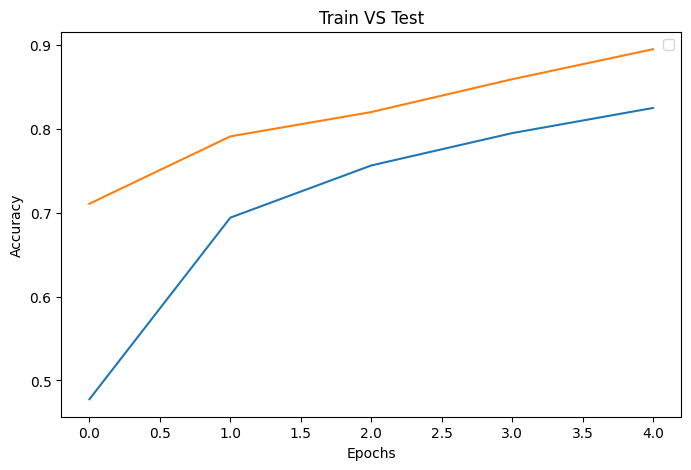

In [45]:
plt.figure(figsize=(8,5))

plt.plot(history.history["accuracy"])
plt.plot(history.history["val_accuracy"])

plt.title("Train VS Test")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

# Loss Graph

C:\Users\Arjun Singh Tomar\AppData\Local\Temp\ipykernel_7012\4595080.py:9: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


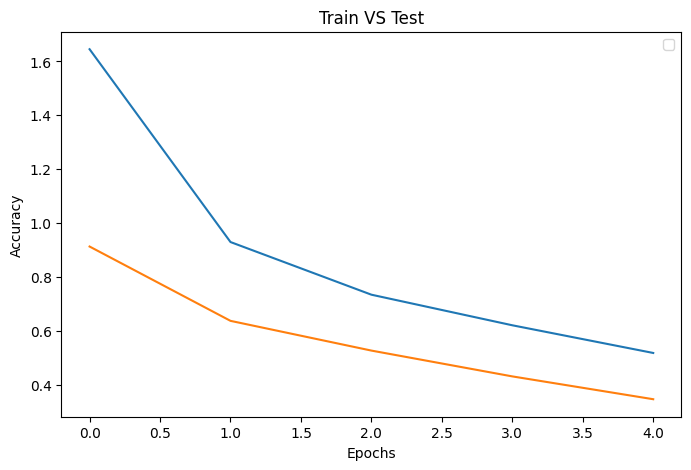

In [46]:
plt.figure(figsize=(8,5))

plt.plot(history.history["loss"])
plt.plot(history.history["val_loss"])

plt.title("Train VS Test")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

# Prediction

In [47]:
y_pred_probs = model.predict(test_ds)

65/65 [==============================] - 2s 22ms/step


In [51]:
# Predict ouptut
import numpy as np
y_pred = np.argmax(y_pred_probs, axis=1)

In [52]:
# Actual output
y_true = np.concatenate(
    [y for x, y in test_ds],
    axis=0
)

# Classification Report

In [53]:
from sklearn.metrics import classification_report,confusion_matrix

In [56]:
print(
    classification_report(
        y_true,
        y_pred,
        target_names=class_names
    )
)

                                             precision    recall  f1-score   support

              Pepper__bell___Bacterial_spot       0.07      0.08      0.07       100
                     Pepper__bell___healthy       0.08      0.07      0.08       148
                      Potato___Early_blight       0.06      0.06      0.06       100
                       Potato___Late_blight       0.03      0.03      0.03       100
                           Potato___healthy       0.00      0.00      0.00        15
                      Tomato_Bacterial_spot       0.11      0.11      0.11       213
                        Tomato_Early_blight       0.05      0.04      0.04       100
                         Tomato_Late_blight       0.07      0.07      0.07       191
                           Tomato_Leaf_Mold       0.08      0.08      0.08        95
                  Tomato_Septoria_leaf_spot       0.11      0.09      0.10       177
Tomato_Spider_mites_Two_spotted_spider_mite       0.08      0.08

In [58]:
# Confusion Matrix
cm = confusion_matrix(y_true, y_pred)

print(cm)

[[ 8  5  5  4  0 13  0 15  3 12  8 11  9  1  6]
 [ 7 11  9  6  0 10 10 18  9  6 11 19 21  2  9]
 [ 6  3  6  5  0  8  1  8 10  6 15  8 17  1  6]
 [ 9  8  5  3  0 19  7  4  2  8  2 11 16  2  4]
 [ 1  2  0  0  0  0  0  3  0  0  1  3  3  0  2]
 [10 17 11 12  1 24 11 19 11 13 19 13 34  4 14]
 [ 7 10  7  3  2 10  4  8  3  7 10  3 17  2  7]
 [10 14  8  8  2 25  6 14  8 17 11 14 32  4 18]
 [ 2  6  4 10  0  6  5 13  8  6  9  9  8  0  9]
 [13 10  6  7  0 17  8 15 11 16 22  9 31  2 10]
 [ 7  7  6  7  0 20  6 10  9 13 14 18 35  3 13]
 [ 8 10  7 10  1 17  6 12  6 10 11 10 16  3 13]
 [19 19 16 17  6 41  9 30 20 17 24 15 61  5 22]
 [ 1  3  1  2  0  3  3  6  2  4  0  2  5  3  2]
 [ 9 11  9 11  2 14  4 13  2 12 12 10 28  4 18]]


# Single Image Prediction

1/1 [==============================] - 0s 462ms/step
Predicted: Tomato_Late_blight


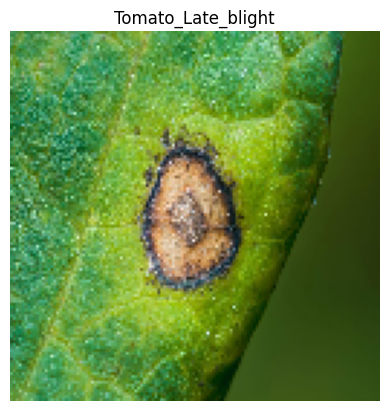

In [59]:
img_path = r"C:\Users\Arjun Singh Tomar\Downloads\leaf.jpeg"

img = keras.utils.load_img(
    img_path,
    target_size=(128, 128)
)

img_array = keras.utils.img_to_array(img)

img_array = img_array / 255.0

img_array = np.expand_dims(img_array, axis=0)

prediction = model.predict(img_array)

predicted_class = class_names[np.argmax(prediction[0])]

print("Predicted:", predicted_class)

plt.imshow(img)
plt.title(predicted_class)
plt.axis("off")
plt.show()

# Save Model

In [60]:
model.save("plant_disease_cnn.keras")

In [61]:
import json

with open("class_names.json", "w") as f:
    json.dump(class_names, f)